1. Import library dan pemanggilan file

In [1]:
from pathlib import Path
from collections import Counter
from functools import lru_cache
import ast
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from rank_bm25 import BM25Okapi
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# Bisa dijalankan dari ARTIKEL (1) ATAU ARTIKEL (1)/Eksperiment3.
CWD = Path.cwd().resolve()
WANTED = ['corpus_faq.csv','kamus_normalisasi.csv','queries_dev.csv','queries_test.csv']
ROOT = next((p for p in [CWD, *list(CWD.parents)[:3]]
             if all((p / f).is_file() for f in WANTED)), None)
if ROOT is None:
    raise FileNotFoundError(f'Dataset tidak ditemukan dari {CWD}. Periksa folder ARTIKEL (1).')
OUTPUT_DIR = ROOT / 'Eksperiment3' / 'hasil_exp3'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
K1, B = 1.5, 0.75
DAFTAR_D = [0,1,2,3]
GAYA = ['formal','informal','singkatan','parafrase','typo']
JALANKAN_TEST_FINAL = False  # True hanya saat evaluasi final setelah semua pilihan dibekukan
pd.set_option('display.max_colwidth', 130)
print('ROOT:', ROOT)
print('OUTPUT:', OUTPUT_DIR)

ROOT: D:\Folder KULIAH\Sistem Temu Kembali\Artikel (1)
OUTPUT: D:\Folder KULIAH\Sistem Temu Kembali\Artikel (1)\Eksperiment3\hasil_exp3


2. Baca data split dan cek integritas

In [2]:
corpus = pd.read_csv(ROOT / 'corpus_faq.csv', dtype={'doc_id': str})
kamus = pd.read_csv(ROOT / 'kamus_normalisasi.csv')
dev_df = pd.read_csv(ROOT / 'queries_dev.csv', dtype={'query_id': str, 'relevant_doc_id': str})
test_df = pd.read_csv(ROOT / 'queries_test.csv', dtype={'query_id': str, 'relevant_doc_id': str})

required = {'query_id','query_text','gaya_kueri','relevant_doc_id','tokens_baseline'}
assert required.issubset(dev_df.columns), required - set(dev_df.columns)
assert required.issubset(test_df.columns), required - set(test_df.columns)
assert {'doc_id','pertanyaan_baku','jawaban'}.issubset(corpus.columns)
assert {'tidak_baku','baku'}.issubset(kamus.columns)
assert corpus['doc_id'].is_unique
assert dev_df['query_id'].is_unique and test_df['query_id'].is_unique
assert set(dev_df['query_id']).isdisjoint(set(test_df['query_id']))
assert set(dev_df['relevant_doc_id']).issubset(set(corpus['doc_id']))
assert set(test_df['relevant_doc_id']).issubset(set(corpus['doc_id']))

def parse_tokens(x):
    tokens = x if isinstance(x,list) else ast.literal_eval(str(x))
    if not isinstance(tokens,list):
        raise TypeError('Kolom tokens_baseline harus berisi list token')
    return tokens

dev_df['tokens_baseline_list'] = dev_df['tokens_baseline'].apply(parse_tokens)
# Test sengaja tidak dipraproses atau dievaluasi saat tuning.
print(f'Dokumen: {len(corpus)} | Kamus: {len(kamus)} | Dev: {len(dev_df)} | Test (disisihkan): {len(test_df)}')
display(dev_df[['query_id','query_text','gaya_kueri','relevant_doc_id']].head(3))

Dokumen: 40 | Kamus: 73 | Dev: 166 | Test (disisihkan): 499


,query_id,query_text,gaya_kueri,relevant_doc_id
0,Q0108,"jika mahasiswa menghasilkan karya atau produk selama PI yang berpotensi didaftarkan HKI, apa yang perlu dilakukan",formal,FAQ039
1,Q0039,"harusnya saya 3 orang ibu, tapi baru 2 orang dan sudah disetujui admin, jadi tidak bisa menambahkan teman saya",formal,FAQ011
2,Q0451,"Mohon info, dosen pembimbing tidak bisa hadir untuk penarikan, bagaimana solusinya apakah bisa diwakilkan dosen lain",parafrase,FAQ025


3. Preprocessing standar Sastrawi dan indeks BM25

In [3]:
stemmer = StemmerFactory().create_stemmer()
stopwords_id = set(StopWordRemoverFactory().get_stop_words())
@lru_cache(maxsize=None)
def stem_cached(token):
    return stemmer.stem(token)

def tokenisasi_dasar(text):
    text = re.sub(r'[^a-z0-9\s]', ' ', str(text).lower())
    return re.sub(r'\s+', ' ', text).strip().split()

def hapus_stopword(tokens):
    return [t for t in tokens if t not in stopwords_id]

def selesai_praproses(tokens):
    return [stem_cached(t) for t in hapus_stopword(tokens)]

def preprocess_standar(text):
    return selesai_praproses(tokenisasi_dasar(text))

corpus['teks_indeks'] = (
    corpus['pertanyaan_baku'].fillna('').astype(str)
    + ' ' + corpus['jawaban'].fillna('').astype(str)
)
corpus_tokens = corpus['teks_indeks'].apply(preprocess_standar).tolist()
doc_ids = corpus['doc_id'].astype(str).tolist()
bm25 = BM25Okapi(corpus_tokens, k1=K1, b=B)

# Lindungi kesetaraan baseline: jika berbeda, hasil eksperimen tidak boleh dibandingkan.
hasil_preprocess_dev = dev_df['query_text'].apply(preprocess_standar).tolist()
beda = [i for i,(a,b) in enumerate(zip(hasil_preprocess_dev, dev_df['tokens_baseline_list'])) if a != b]
print('Jumlah tokenisasi berbeda terhadap baseline:', len(beda))
if beda:
    i=beda[0]
    print('Contoh query:', dev_df.iloc[i]['query_text'])
    print('CSV :',dev_df.iloc[i]['tokens_baseline_list'])
    print('Baru:',hasil_preprocess_dev[i])
    raise ValueError('Pipeline Sastrawi tidak sama dengan baseline. Perbaiki sebelum melanjutkan.')
print(f'Indeks BM25: {len(doc_ids)} FAQ, k1={K1}, b={B}, avgdl={bm25.avgdl:.2f}')

Jumlah tokenisasi berbeda terhadap baseline: 0
Indeks BM25: 40 FAQ, k1=1.5, b=0.75, avgdl=26.23


4. Membentuk kosakata acuan Levenshtein

In [4]:
corpus_surface = []
for text in corpus['teks_indeks']:
    corpus_surface.extend(hapus_stopword(tokenisasi_dasar(text)))
corpus_stemmed = [t for doc in corpus_tokens for t in doc]
vocab_freq = Counter(corpus_surface + corpus_stemmed)
vocab_acuan = set(vocab_freq) | stopwords_id
vocab_urut = sorted(vocab_acuan)  # tiebreak deterministik
print('Jumlah kosakata acuan:',len(vocab_acuan))

Jumlah kosakata acuan: 564


5. Normalisasi berbasis kamus

In [5]:
kamus_valid = kamus.dropna(subset=['tidak_baku','baku']).copy()
kamus_valid = kamus_valid[
    ~kamus_valid['baku'].astype(str).str.contains('/', regex=False)
]
# Jangan menebak entri kosong/ambigu. Prioritaskan kecocokan frasa terpanjang.
pasangan_kamus = []
for r in kamus_valid.itertuples(index=False):
    asal = tuple(tokenisasi_dasar(r.tidak_baku))
    tujuan = tuple(tokenisasi_dasar(r.baku))
    if asal and tujuan:
        pasangan_kamus.append((asal, tujuan))
pasangan_kamus.sort(key=lambda p: -len(p[0]))

# Deteksi konflik: sumber sama tetapi padanan berbeda.
seen = {}
for asal, tujuan in pasangan_kamus:
    if asal in seen and seen[asal] != tujuan:
        raise ValueError(f'Kamus konflik: {asal} menjadi {seen[asal]} atau {tujuan}')
    seen[asal] = tujuan

def normalisasi_kamus(teks):
    toks = tokenisasi_dasar(teks)
    hasil, proteksi, log = [], [], []
    i=0
    while i < len(toks):
        cocok=False
        for asal, tujuan in pasangan_kamus:
            if tuple(toks[i:i+len(asal)]) == asal:
                hasil.extend(tujuan)
                proteksi.extend([True]*len(tujuan))
                log.append(f"{' '.join(asal)} -> {' '.join(tujuan)}")
                i += len(asal)
                cocok=True
                break
        if not cocok:
            hasil.append(toks[i]); proteksi.append(False); i+=1
    return hasil, proteksi, log

print('Kamus valid:',len(pasangan_kamus),'dari',len(kamus),'baris')

Kamus valid: 68 dari 73 baris


6. Levenshtein Distance: aturan panjang kata dan referensi dari Eksperimen 2

In [6]:
@lru_cache(maxsize=None)
def jarak_levenshtein(a,b):
    if len(a) < len(b):
        a,b=b,a
    prev=list(range(len(b)+1))
    for i,ca in enumerate(a,1):
        now=[i]
        for j,cb in enumerate(b,1):
            now.append(min(prev[j]+1, now[-1]+1, prev[j-1]+(ca!=cb)))
        prev=now
    return prev[-1]

@lru_cache(maxsize=None)
def kandidat_terdekat(token):
    best, d_best, f_best = token, float('inf'), -1
    for calon in vocab_urut:
        if abs(len(token)-len(calon)) > d_best:
            continue
        d=jarak_levenshtein(token,calon)
        freq=vocab_freq[calon]
        if d < d_best or (d == d_best and freq > f_best):
            best,d_best,f_best=calon,d,freq
    return best,d_best

def koreksi_lev(token, batas):
    if batas <= 0 or token.isdigit() or len(token) < 3:
        return token, 0, False
    if token in vocab_acuan or stem_cached(token) in vocab_acuan:
        return token, 0, False
    calon,jarak=kandidat_terdekat(token)
    batas_efektif=min(batas,1) if len(token)<=4 else batas
    if jarak <= batas_efektif:
        return calon,jarak,True
    return token,jarak,False

7. Gabungan kamus → Levenshtein → stopword → stemming

In [7]:
def preprocess_exp3(teks, batas):
    toks, protected, log_kamus=normalisasi_kamus(teks)
    setelah_lev, log_lev=[],[]
    n_diperiksa=0
    for token, dari_kamus in zip(toks,protected):
        if dari_kamus:
            setelah_lev.append(token)
            continue
        n_diperiksa += 1
        koreksi,d,berubah=koreksi_lev(token,batas)
        setelah_lev.append(koreksi)
        if berubah:
            log_lev.append(f'{token} -> {koreksi} (d={d})')
    return {
        'tokens': selesai_praproses(setelah_lev),
        'log_kamus':log_kamus, 'log_lev':log_lev,
        'n_kamus':len(log_kamus), 'n_lev':len(log_lev),
        'n_token_setelah_kamus':len(toks),
        'n_token_diperiksa_lev':n_diperiksa,
    }

for contoh in ['dospem blm verif berkas pi gmn caranya', 'pengajuann surat apakah bisa']:
    r=preprocess_exp3(contoh, 2)
    print(contoh, '\n  kamus:',r['log_kamus'],'\n  levenshtein:',r['log_lev'],'\n  tokens:',r['tokens'])

dospem blm verif berkas pi gmn caranya 
  kamus: ['dospem -> dosen pembimbing', 'blm -> belum', 'verif -> verifikasi', 'pi -> praktik industri', 'gmn -> bagaimana'] 
  levenshtein: [] 
  tokens: ['dosen', 'bimbing', 'verifikasi', 'berkas', 'praktik', 'industri', 'bagaimana', 'cara']
pengajuann surat apakah bisa 
  kamus: [] 
  levenshtein: ['pengajuann -> pengajuan (d=1)'] 
  tokens: ['aju', 'surat']


8. Fungsi pengambilan peringkat dan penghitungan hasil setiap kueri

In [8]:
def ranking_bm25(tokens):
    skor=bm25.get_scores(tokens)
    idx=np.argsort(skor)[::-1]  # ikut baseline dan dua eksperimen sebelumnya
    return [doc_ids[i] for i in idx], float(skor[idx[0]])

def evaluasi_exp3(df, d):
    rows=[]
    for r in df.itertuples(index=False):
        info=preprocess_exp3(r.query_text,d)
        urutan,top_score=ranking_bm25(info['tokens'])
        gold=str(r.relevant_doc_id)
        rank=urutan.index(gold)+1 if gold in urutan else None
        rows.append({
            'query_id':r.query_id, 'gaya_kueri':r.gaya_kueri,
            'query_text':r.query_text, 'relevant_doc_id':gold,
            'd_levenshtein':d, 'prediksi_top1':urutan[0],
            'skor_top1':top_score, 'peringkat_benar':rank,
            'hit1':int(rank==1), 'hit3':int(rank is not None and rank<=3),
            'hit5':int(rank is not None and rank<=5),
            'reciprocal_rank':(1/rank if rank else 0.0),
            'n_kamus':info['n_kamus'], 'n_lev':info['n_lev'],
            'n_token_setelah_kamus':info['n_token_setelah_kamus'],
            'n_token_diperiksa_lev':info['n_token_diperiksa_lev'],
            'normalisasi_kamus':' | '.join(info['log_kamus']),
            'koreksi_levenshtein':' | '.join(info['log_lev']),
            'tokens_exp3':str(info['tokens']),
        })
    return pd.DataFrame(rows)

def ringkasan(df, T_BM25):
    if len(df)==0:
        raise ValueError('Tidak bisa mengevaluasi subset kosong')
    reject=df['skor_top1'] < T_BM25
    correct=df['hit1'].astype(bool)
    return {
        'N':len(df),'Hit@1':df['hit1'].mean(),
        'Hit@3':df['hit3'].mean(),'Hit@5':df['hit5'].mean(),
        'MRR':df['reciprocal_rank'].mean(),
        'Fallback Rate':reject.mean(),
        'Diterima':int((~reject).sum()), 'Ditolak':int(reject.sum()),
        'Top1_Benar_Ditolak':int((correct & reject).sum()),
        'Top1_Salah_Ditolak':int((~correct & reject).sum()),
        'Hit@1_setelah_fallback':(correct & ~reject).mean(),
        'MRR_setelah_fallback':(df['reciprocal_rank']*(~reject)).mean(),
        'Kueri dinormalisasi':int(((df['n_kamus']+df['n_lev'])>0).sum()),
        'Penggantian kamus':int(df['n_kamus'].sum()),
        'Koreksi Levenshtein':int(df['n_lev'].sum()),
        'Rasio koreksi (token diperiksa)':(
            df['n_lev'].sum()/max(1,df['n_token_diperiksa_lev'].sum()))
    }

9. Kalibrasi threshold skor BM25 pada baseline-development set

In [9]:
baseline_records=[]
for r in dev_df.itertuples(index=False):
    token=parse_tokens(r.tokens_baseline)
    urutan,top_score=ranking_bm25(token)
    baseline_records.append({
        'query_id':r.query_id, 'skor_top1':top_score,
        'top1_benar':int(urutan[0]==str(r.relevant_doc_id))
    })
baseline_dev=pd.DataFrame(baseline_records)
assert baseline_dev['query_id'].is_unique

# Validasi terhadap hasil yang tersimpan pada notebook baseline, tanpa mengubah kode baseline.
print('Hit@1 baseline dev dari indeks ini:',round(baseline_dev['top1_benar'].mean(),4))
print('Label benar top1:',int(baseline_dev['top1_benar'].sum()),'dari',len(baseline_dev))

scores=baseline_dev['skor_top1'].to_numpy(dtype=float)
correct=baseline_dev['top1_benar'].to_numpy(dtype=bool)
if not np.isfinite(scores).all():
    raise ValueError('Skor BM25 mengandung NaN/inf. Periksa index atau dataset.')
if not (correct.any() and (~correct).any()):
    raise ValueError('Tuning threshold fallback butuh contoh top1 benar dan salah di dev. '
                     'Tambahkan validation negatif atau tetapkan threshold terpisah secara terdokumentasi.')

unique_scores=np.unique(scores)
ambang=[float(np.nextafter(unique_scores[0],-np.inf))]
ambang.extend(((unique_scores[:-1]+unique_scores[1:])/2).tolist())
ambang.append(float(np.nextafter(unique_scores[-1],np.inf)))

baris=[]
for T in ambang:
    terima=scores >= T
    recall_jawaban_benar=float(terima[correct].mean())
    penolakan_jawaban_salah=float((~terima)[~correct].mean())
    ba=(recall_jawaban_benar+penolakan_jawaban_salah)/2
    baris.append({
        'Threshold_BM25':T,'Balanced_Accuracy_Proxy':ba,
        'Recall_Terima_Top1_Benar':recall_jawaban_benar,
        'Reject_Top1_Salah':penolakan_jawaban_salah,
        'Fallback_Rate_Baseline_Dev':float((~terima).mean())
    })
tuning_bm25=pd.DataFrame(baris).sort_values(
    ['Balanced_Accuracy_Proxy','Recall_Terima_Top1_Benar',
     'Fallback_Rate_Baseline_Dev','Threshold_BM25'],
    ascending=[False,False,True,True],kind='stable'
).reset_index(drop=True)
T_BM25=float(tuning_bm25.iloc[0]['Threshold_BM25'])
print('Threshold skor BM25 terkalibrasi dari BASELINE DEV:',round(T_BM25,6))
print('Metode: maksimum balanced accuracy (proksi top1 benar vs salah)')
display(tuning_bm25.head(8).round(4))
tuning_bm25.to_csv(OUTPUT_DIR/'tuning_threshold_skor_bm25_baseline_dev.csv',index=False)

Hit@1 baseline dev dari indeks ini: 0.9398
Label benar top1: 156 dari 166
Threshold skor BM25 terkalibrasi dari BASELINE DEV: 7.25008
Metode: maksimum balanced accuracy (proksi top1 benar vs salah)


,Threshold_BM25,Balanced_Accuracy_Proxy,Recall_Terima_Top1_Benar,Reject_Top1_Salah,Fallback_Rate_Baseline_Dev
0,7.2501,0.9808,0.9615,1.0,0.0964
1,7.7571,0.9776,0.9551,1.0,0.1024
2,8.3428,0.9744,0.9487,1.0,0.1084
3,8.5189,0.9712,0.9423,1.0,0.1145
4,8.6201,0.9647,0.9295,1.0,0.1265
5,8.6697,0.9583,0.9167,1.0,0.1386
6,8.7116,0.9551,0.9103,1.0,0.1446
7,8.8333,0.9519,0.9038,1.0,0.1506


10. Tuning ambang Levenshtein 0, 1, 2, 3 pada dev saja

In [10]:
hasil_per_d={}
baris_tuning=[]
for d in DAFTAR_D:
    detail=evaluasi_exp3(dev_df,d)
    hasil_per_d[d]=detail
    m=ringkasan(detail,T_BM25)
    typo=detail.loc[detail['gaya_kueri']=='typo']
    baris_tuning.append({
        'Threshold':d, 'N':m['N'],
        'Hit@1':m['Hit@1'],'Hit@3':m['Hit@3'],'Hit@5':m['Hit@5'],'MRR':m['MRR'],
        'Fallback Rate':m['Fallback Rate'],
        'Kueri_Dikoreksi':m['Kueri dinormalisasi'],
        'Penggantian_Kamus':m['Penggantian kamus'],
        'Koreksi_Levenshtein':m['Koreksi Levenshtein'],
        'Rasio_Koreksi':m['Rasio koreksi (token diperiksa)'],
        'Hit@1_Typo':float(typo['hit1'].mean()) if len(typo) else np.nan,
        'MRR_Typo':float(typo['reciprocal_rank'].mean()) if len(typo) else np.nan,
    })
tuning_lev=pd.DataFrame(baris_tuning)
display(tuning_lev.round(4))

ranked=tuning_lev.sort_values(
    ['MRR','Hit@1','Koreksi_Levenshtein','Threshold'],
    ascending=[False,False,True,True],kind='stable'
)
best_d=int(ranked.iloc[0]['Threshold'])
print('d Levenshtein terbaik di dev:',best_d)
print('Threshold skor BM25 yang dibekukan:',round(T_BM25,6))
if best_d==0:
    print('PERINGATAN: d=0 berarti konfigurasi kamus saja; penambahan Levenshtein tidak memberi keuntungan di dev.')
tuning_lev.to_csv(OUTPUT_DIR/'tuning_threshold_levenshtein_exp3_dev.csv',index=False)

,Threshold,N,Hit@1,Hit@3,Hit@5,MRR,Fallback Rate,Kueri_Dikoreksi,Penggantian_Kamus,Koreksi_Levenshtein,Rasio_Koreksi,Hit@1_Typo,MRR_Typo
0,0,166,0.9096,0.9759,0.994,0.9443,0.0422,145,298,0,0.0000,0.875,0.9140
1,1,166,0.9096,0.9940,1.000,0.9490,0.0361,152,298,95,0.0532,0.875,0.9333
2,2,166,0.9096,0.9940,1.000,0.9490,0.0301,160,298,176,0.0985,0.875,0.9333
3,3,166,0.9277,0.9940,1.000,0.9580,0.0241,162,298,209,0.1170,0.900,0.9458


d Levenshtein terbaik di dev: 3
Threshold skor BM25 yang dibekukan: 7.25008


11. Evaluasi akhir dev pada d terbaik dan T_BM25 terkalibrasi

In [11]:
hasil_dev=hasil_per_d[best_d].copy()
hasil_dev['ditolak_fallback']=(hasil_dev['skor_top1']<T_BM25)
hasil_dev['status_jawaban']=np.where(hasil_dev['ditolak_fallback'],'FALLBACK','DITERIMA')
ringkasan_dev=pd.DataFrame([{'Konfigurasi':'BM25 + Kamus + Levenshtein',
                             'd_Lev':best_d,'T_BM25':T_BM25,
                             **ringkasan(hasil_dev,T_BM25)}])
print('=== Evaluasi Eksperimen 3 pada DEVELOPMENT SET ===')
display(ringkasan_dev.round(4))
ringkasan_dev.to_csv(OUTPUT_DIR/'ringkasan_exp3_dev.csv',index=False)
hasil_dev.to_csv(OUTPUT_DIR/'detail_exp3_dev.csv',index=False)

=== Evaluasi Eksperimen 3 pada DEVELOPMENT SET ===


,Konfigurasi,d_Lev,T_BM25,N,Hit@1,Hit@3,Hit@5,MRR,Fallback Rate,Diterima,Ditolak,Top1_Benar_Ditolak,Top1_Salah_Ditolak,Hit@1_setelah_fallback,MRR_setelah_fallback,Kueri dinormalisasi,Penggantian kamus,Koreksi Levenshtein,Rasio koreksi (token diperiksa)
0,BM25 + Kamus + Levenshtein,3,7.2501,166,0.9277,0.994,1.0,0.958,0.0241,162,4,2,2,0.9157,0.941,162,298,209,0.117


12. Evaluasi Eksperimen 3 menurut lima gaya kueri

In [12]:
baris=[]
for gaya in GAYA:
    subset=hasil_dev[hasil_dev['gaya_kueri']==gaya]
    if len(subset):
        baris.append({'Gaya Kueri':gaya, **ringkasan(subset,T_BM25)})
per_gaya=pd.DataFrame(baris)
print('=== Evaluasi PER GAYA pada development set ===')
display(per_gaya.round(4))
per_gaya.to_csv(OUTPUT_DIR/'per_gaya_exp3_dev.csv',index=False)

=== Evaluasi PER GAYA pada development set ===


,Gaya Kueri,N,Hit@1,Hit@3,Hit@5,MRR,Fallback Rate,Diterima,Ditolak,Top1_Benar_Ditolak,Top1_Salah_Ditolak,Hit@1_setelah_fallback,MRR_setelah_fallback,Kueri dinormalisasi,Penggantian kamus,Koreksi Levenshtein,Rasio koreksi (token diperiksa)
0,formal,20,0.8500,1.0000,1.0,0.9167,0.050,19,1,1,0,0.8000,0.8667,20,30,9,0.0443
1,informal,36,1.0000,1.0000,1.0,1.0000,0.000,36,0,0,0,1.0000,1.0000,35,75,28,0.0805
2,singkatan,35,0.9429,1.0000,1.0,0.9667,0.000,35,0,0,0,0.9429,0.9667,35,109,22,0.0703
3,parafrase,35,0.9143,0.9714,1.0,0.9438,0.000,35,0,0,0,0.9143,0.9438,32,39,35,0.0748
4,typo,40,0.9000,1.0000,1.0,0.9458,0.075,37,3,1,2,0.8750,0.9000,40,45,115,0.2527


13. Audit normalisasi dan perubahan pemeringkatan dibanding d=0 di Eksperimen 3

In [13]:
acuan=hasil_per_d[0][['query_id','peringkat_benar','hit1']].rename(
    columns={'peringkat_benar':'peringkat_d0','hit1':'hit1_d0'})
audit=hasil_dev.merge(acuan,on='query_id',validate='one_to_one')
audit['perubahan_rank']=audit['peringkat_d0']-audit['peringkat_benar']
audit['status']=np.select([audit['perubahan_rank']>0,audit['perubahan_rank']<0],
                          ['Membaik','Memburuk'],default='Tetap')
print('Perubahan peringkat akibat PENAMBAHAN Levenshtein di atas kamus:')
display(audit['status'].value_counts().to_frame('n'))
kolom=['query_id','gaya_kueri','query_text','normalisasi_kamus',
       'koreksi_levenshtein','peringkat_d0','peringkat_benar','status']
display(audit.loc[audit['status']!='Tetap',kolom].head(20))
audit.to_csv(OUTPUT_DIR/'audit_normalisasi_dan_rank_exp3_dev.csv',index=False)
hasil_dev.loc[hasil_dev['hit1']==0].to_csv(OUTPUT_DIR/'kesalahan_top1_exp3_dev.csv',index=False)

Perubahan peringkat akibat PENAMBAHAN Levenshtein di atas kamus:


,n
status,
Tetap,159
Membaik,6
Memburuk,1


,query_id,gaya_kueri,query_text,normalisasi_kamus,koreksi_levenshtein,peringkat_d0,peringkat_benar,status
14,Q0253,typo,"harusnya saya 3 orang ibu, tapi baru 2 rang dan sudah disetujui dmin, jadi tidak bisa menambahkan eman saya",,orang -> ulang (d=2) | ibu -> itu (d=1) | rang -> yang (d=1) | dmin -> admin (d=1) | eman -> aman (d=1),9,3,Membaik
42,Q0254,typo,"ahrusnya saya 3 orang ibu, tapi baru 2 orang dan sduah disetujui admin, jadi tdiak bisa menambahkan teman saya",,ahrusnya -> akunnya (d=3) | orang -> ulang (d=2) | ibu -> itu (d=1) | orang -> ulang (d=2) | sduah -> salah (d=2) | tdiak -> t...,1,2,Memburuk
46,Q0127,informal,"kak, izin ibu, gak muncul notifikasi email saat registrasi akun SIPI",kak -> kakak | gak -> tidak | sipi -> sistem informasi praktik industri,ibu -> itu (d=1) | muncul -> menu (d=3) | notifikasi -> verifikasi (d=3),2,1,Membaik
79,Q0252,typo,"harusnya saya 3 oragn ibu, tapi baru 2 orang dan sudah disetjuui admin, jadi tidak bisa menambhakan teman saya",,oragn -> aman (d=3) | ibu -> itu (d=1) | orang -> ulang (d=2) | disetjuui -> disetujui (d=2),2,1,Membaik
87,Q0125,singkatan,"mhn info, izin ibu, tdk muncul notifikasi email saat registrasi akun SIPI",tdk -> tidak | sipi -> sistem informasi praktik industri,ibu -> itu (d=1) | muncul -> menu (d=3) | notifikasi -> verifikasi (d=3),2,1,Membaik
90,Q0128,typo,"izin ibu, tiak muncul notifikasi emil saat registrasi akun SIPI",sipi -> sistem informasi praktik industri,ibu -> itu (d=1) | tiak -> tiap (d=1) | muncul -> menu (d=3) | notifikasi -> verifikasi (d=3) | emil -> email (d=1),5,1,Membaik
158,Q0011,typo,knpa akun ku blum terverfikasi ibuu,knpa -> kenapa,blum -> belum (d=1) | terverfikasi -> terverifikasi (d=1),4,2,Membaik


14. Visualisasi tuning dan evaluasi per gaya kueri

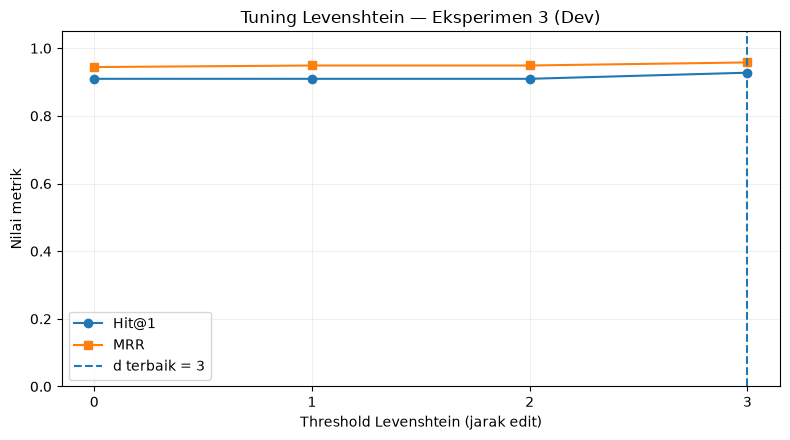

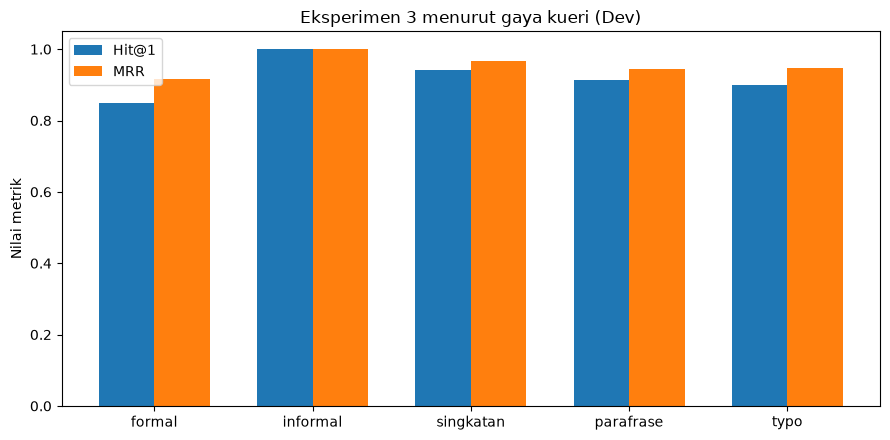

In [14]:
plt.figure(figsize=(8,4.5))
plt.plot(tuning_lev['Threshold'],tuning_lev['Hit@1'],marker='o',label='Hit@1')
plt.plot(tuning_lev['Threshold'],tuning_lev['MRR'],marker='s',label='MRR')
plt.axvline(best_d,ls='--',label=f'd terbaik = {best_d}')
plt.xlabel('Threshold Levenshtein (jarak edit)');plt.ylabel('Nilai metrik')
plt.title('Tuning Levenshtein — Eksperimen 3 (Dev)')
plt.xticks(DAFTAR_D);plt.ylim(0,1.05);plt.grid(alpha=.2);plt.legend();plt.tight_layout()
plt.savefig(OUTPUT_DIR/'fig_tuning_lev_exp3_dev.png',dpi=180)
plt.show()

x=np.arange(len(per_gaya)); lebar=.35
plt.figure(figsize=(9,4.5))
plt.bar(x-lebar/2,per_gaya['Hit@1'],lebar,label='Hit@1')
plt.bar(x+lebar/2,per_gaya['MRR'],lebar,label='MRR')
plt.xticks(x,per_gaya['Gaya Kueri']);plt.ylim(0,1.05)
plt.title('Eksperimen 3 menurut gaya kueri (Dev)');plt.ylabel('Nilai metrik')
plt.legend();plt.tight_layout()
plt.savefig(OUTPUT_DIR/'fig_per_gaya_exp3_dev.png',dpi=180)
plt.show()